<a href="https://colab.research.google.com/github/kamilabalabatyr/AI-Fundamentals/blob/main/Lab2_Fuzzy_WashingMachine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 18.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

dirtiness = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'dirtiness')
load      = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'load')
wash_time = ctrl.Consequent(np.arange(0, 121, 1), 'wash_time')

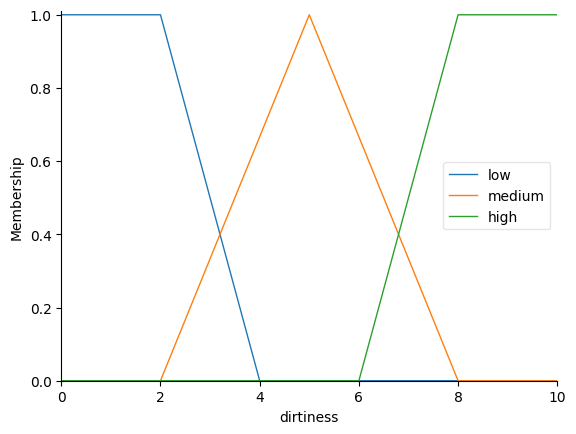

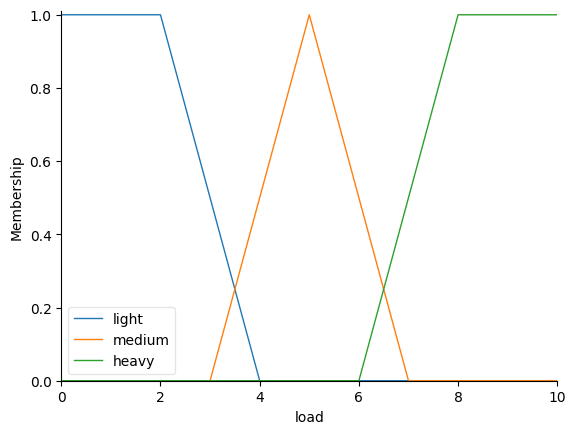

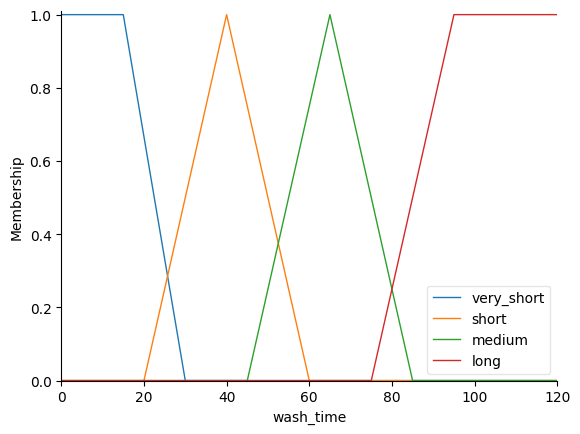

In [ ]:
# Dirtiness (0–10)
dirtiness['low']    = fuzz.trapmf(dirtiness.universe, [0, 0, 2, 4])
dirtiness['medium'] = fuzz.trimf(dirtiness.universe,  [2, 5, 8])
dirtiness['high']   = fuzz.trapmf(dirtiness.universe, [6, 8, 10, 10])

# Load (0–10 kg)
load['light']  = fuzz.trapmf(load.universe, [0, 0, 2, 4])
load['medium'] = fuzz.trimf(load.universe,  [3, 5, 7])
load['heavy']  = fuzz.trapmf(load.universe, [6, 8, 10, 10])

# Wash time (0–120 min)
wash_time['very_short'] = fuzz.trapmf(wash_time.universe, [0, 0, 15, 30])
wash_time['short']      = fuzz.trimf(wash_time.universe,  [20, 40, 60])
wash_time['medium']     = fuzz.trimf(wash_time.universe,  [45, 65, 85])
wash_time['long']       = fuzz.trapmf(wash_time.universe, [75, 95, 120, 120])

# Plot all membership functions
dirtiness.view()
load.view()
wash_time.view()
plt.show()

Wash time: 78.9 min


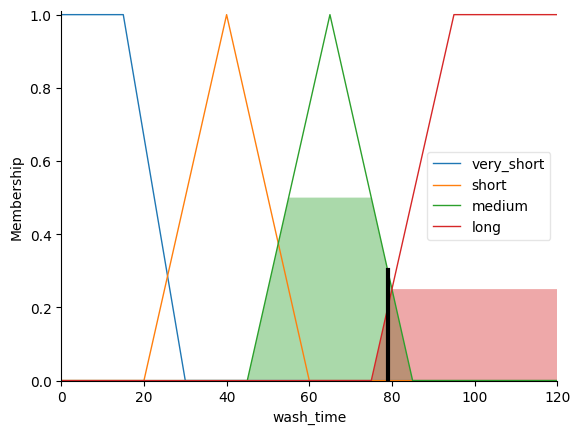

In [ ]:
#Fuzzy rules (full 3x3 rule base)
rule1 = ctrl.Rule(dirtiness['low']    & load['light'],  wash_time['very_short'])
rule2 = ctrl.Rule(dirtiness['low']    & load['medium'], wash_time['short'])
rule3 = ctrl.Rule(dirtiness['low']    & load['heavy'],  wash_time['medium'])

rule4 = ctrl.Rule(dirtiness['medium'] & load['light'],  wash_time['short'])
rule5 = ctrl.Rule(dirtiness['medium'] & load['medium'], wash_time['medium'])
rule6 = ctrl.Rule(dirtiness['medium'] & load['heavy'],  wash_time['long'])

rule7 = ctrl.Rule(dirtiness['high']   & load['light'],  wash_time['medium'])
rule8 = ctrl.Rule(dirtiness['high']   & load['medium'], wash_time['long'])
rule9 = ctrl.Rule(dirtiness['high']   & load['heavy'],  wash_time['long'])

rules = [rule1, rule2, rule3, rule4, rule5, rule6, rule7, rule8, rule9]

#fuzzy inference system
washing_ctrl = ctrl.ControlSystem(rules)
washing_sim  = ctrl.ControlSystemSimulation(washing_ctrl)

washing_sim.input['dirtiness'] = 6.5
washing_sim.input['load'] = 4
washing_sim.compute()
print("Wash time:", round(washing_sim.output['wash_time'], 1), "min")

wash_time.view(sim=washing_sim)
plt.show()


Dirtiness = 1, Load = 1 kg  ->  Wash time = 11.7 min
  Rule 1: IF dirtiness is low (1.00) AND load is light (1.00) THEN very_short  -> strength 1.00


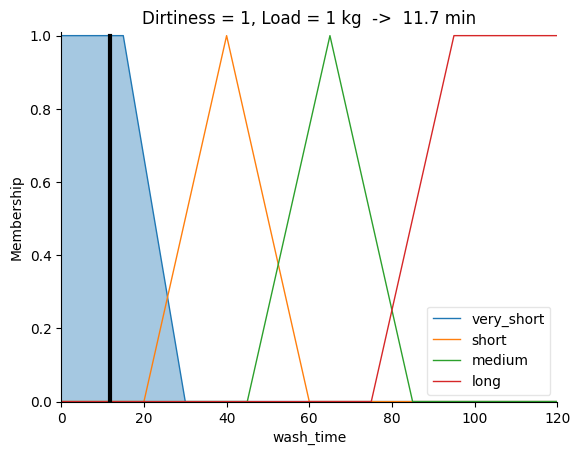


Dirtiness = 2, Load = 8 kg  ->  Wash time = 65.0 min
  Rule 3: IF dirtiness is low (1.00) AND load is heavy (1.00) THEN medium  -> strength 1.00


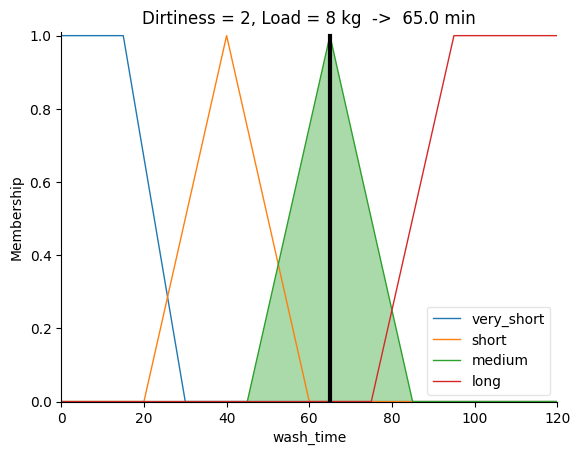


Dirtiness = 5, Load = 5 kg  ->  Wash time = 65.0 min
  Rule 5: IF dirtiness is medium (1.00) AND load is medium (1.00) THEN medium  -> strength 1.00


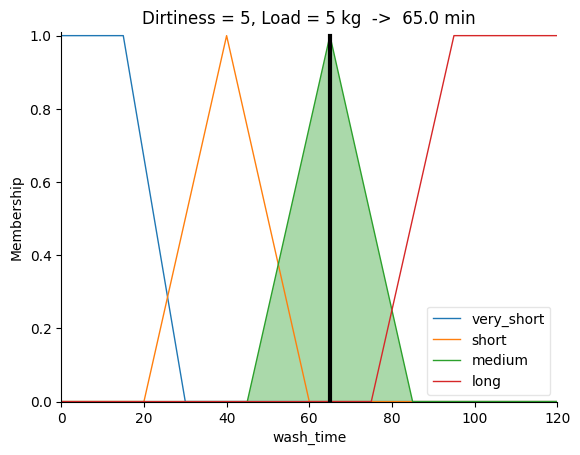


Dirtiness = 6.5, Load = 4 kg  ->  Wash time = 78.9 min
  Rule 5: IF dirtiness is medium (0.50) AND load is medium (0.50) THEN medium  -> strength 0.50
  Rule 8: IF dirtiness is high (0.25) AND load is medium (0.50) THEN long  -> strength 0.25


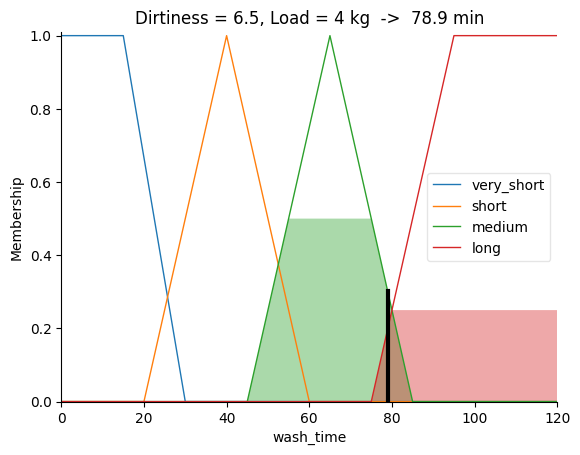


Dirtiness = 9, Load = 2 kg  ->  Wash time = 65.0 min
  Rule 7: IF dirtiness is high (1.00) AND load is light (1.00) THEN medium  -> strength 1.00


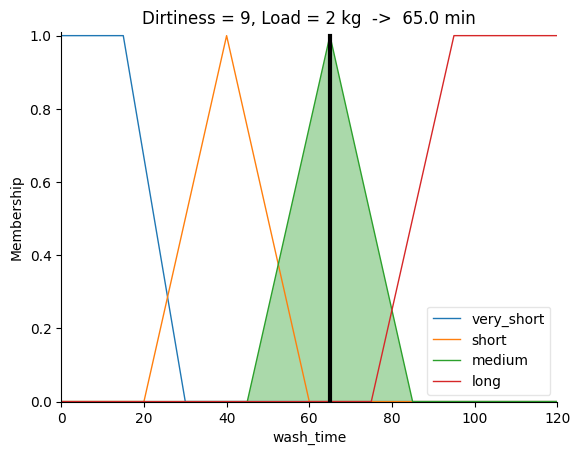


Dirtiness = 9, Load = 9 kg  ->  Wash time = 102.0 min
  Rule 9: IF dirtiness is high (1.00) AND load is heavy (1.00) THEN long  -> strength 1.00


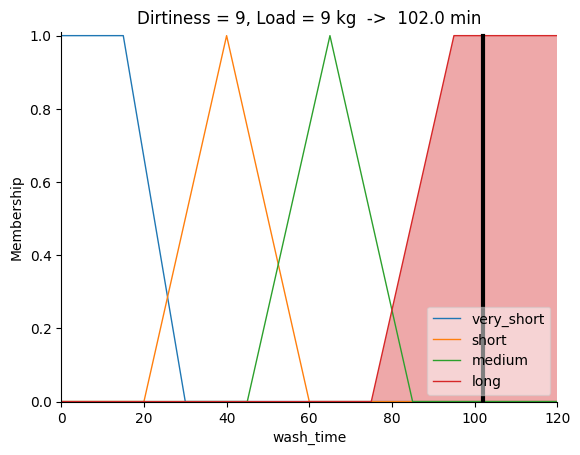

In [ ]:
# Rule table
rule_table = [
    ('low', 'light', 'very_short'), ('low', 'medium', 'short'),   ('low', 'heavy', 'medium'),
    ('medium', 'light', 'short'),   ('medium', 'medium', 'medium'), ('medium', 'heavy', 'long'),
    ('high', 'light', 'medium'),    ('high', 'medium', 'long'),    ('high', 'heavy', 'long'),
]

def run_case(d, l):
    washing_sim.input['dirtiness'] = d
    washing_sim.input['load'] = l
    washing_sim.compute()
    out = washing_sim.output['wash_time']

    print(f"\nDirtiness = {d}, Load = {l} kg  ->  Wash time = {out:.1f} min")
    for i, (ds, ls, os_) in enumerate(rule_table, start=1):
        md = fuzz.interp_membership(dirtiness.universe, dirtiness[ds].mf, d)
        ml = fuzz.interp_membership(load.universe, load[ls].mf, l)
        strength = min(md, ml)
        if strength > 0:
            print(f"  Rule {i}: IF dirtiness is {ds} ({md:.2f}) AND load is {ls} ({ml:.2f}) "
                  f"THEN {os_}  -> strength {strength:.2f}")

    wash_time.view(sim=washing_sim)
    plt.title(f"Dirtiness = {d}, Load = {l} kg  ->  {out:.1f} min")
    plt.show()
    return out

test_cases = [
    (1, 1),    # almost clean, small load
    (2, 8),    # clean but heavy load
    (5, 5),    # everything medium
    (6.5, 4),  # our earlier example
    (9, 2),    # very dirty, light load
    (9, 9),    # very dirty, heavy load
]

results = []
for d, l in test_cases:
    results.append((d, l, run_case(d, l)))

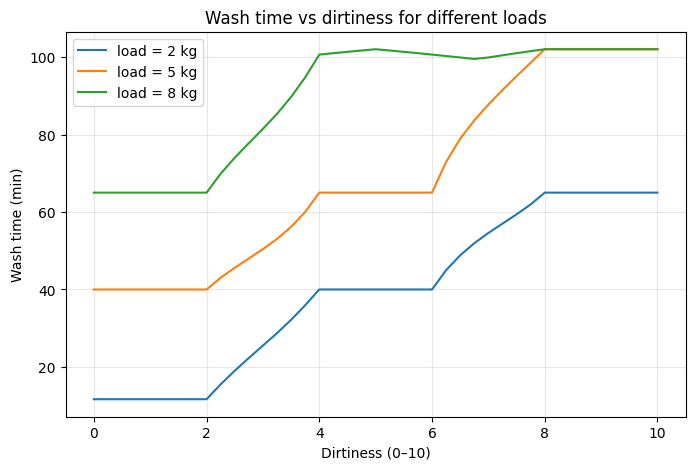

In [ ]:
def predict(sim, d, l):
    sim.input['dirtiness'] = d
    sim.input['load'] = l
    sim.compute()
    return sim.output['wash_time']

d_vals = np.arange(0, 10.01, 0.25)

plt.figure(figsize=(8, 5))
for l in [2, 5, 8]:
    outs = [predict(washing_sim, d, l) for d in d_vals]
    plt.plot(d_vals, outs, label=f"load = {l} kg")
plt.xlabel("Dirtiness (0–10)")
plt.ylabel("Wash time (min)")
plt.title("Wash time vs dirtiness for different loads")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

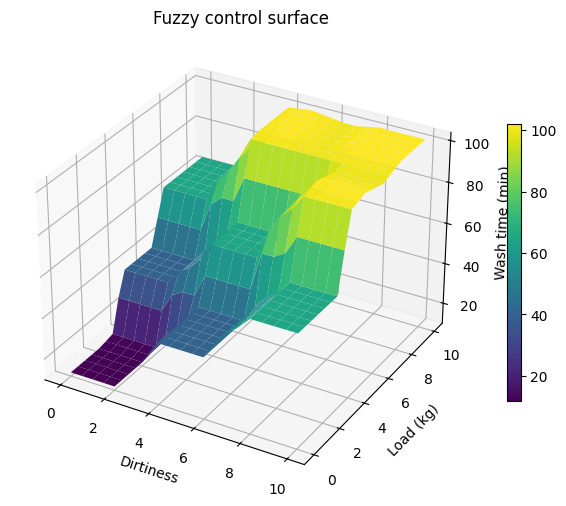

In [ ]:
d_grid = np.arange(0, 10.01, 0.5)
l_grid = np.arange(0, 10.01, 0.5)
D, L = np.meshgrid(d_grid, l_grid)
Z = np.zeros_like(D)

for i in range(D.shape[0]):
    for j in range(D.shape[1]):
        Z[i, j] = predict(washing_sim, D[i, j], L[i, j])

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(D, L, Z, cmap='viridis', edgecolor='none')
ax.set_xlabel("Dirtiness"); ax.set_ylabel("Load (kg)"); ax.set_zlabel("Wash time (min)")
ax.set_title("Fuzzy control surface")
fig.colorbar(surf, shrink=0.6)
plt.show()

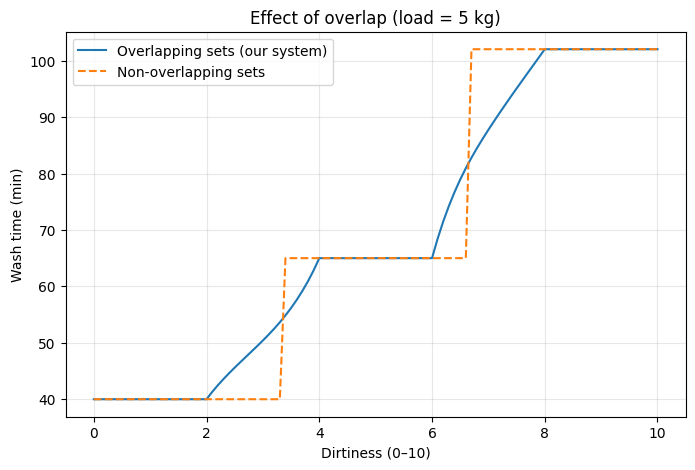

In [ ]:
#no real overlap sets
dirt_crisp = ctrl.Antecedent(np.arange(0, 10.1, 0.1), 'dirtiness')
dirt_crisp['low']    = fuzz.trapmf(dirt_crisp.universe, [0, 0, 3.3, 3.4])
dirt_crisp['medium'] = fuzz.trapmf(dirt_crisp.universe, [3.3, 3.4, 6.6, 6.7])
dirt_crisp['high']   = fuzz.trapmf(dirt_crisp.universe, [6.6, 6.7, 10, 10])

rules_crisp = [ctrl.Rule(dirt_crisp[ds] & load[ls], wash_time[os_])
               for ds, ls, os_ in rule_table]
sim_crisp = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules_crisp))

d_vals = np.arange(0, 10.01, 0.1)
out_fuzzy = [predict(washing_sim, d, 5) for d in d_vals]
out_crisp = [predict(sim_crisp,   d, 5) for d in d_vals]

plt.figure(figsize=(8, 5))
plt.plot(d_vals, out_fuzzy, label="Overlapping sets (our system)")
plt.plot(d_vals, out_crisp, '--', label="Non-overlapping sets")
plt.xlabel("Dirtiness (0–10)"); plt.ylabel("Wash time (min)")
plt.title("Effect of overlap (load = 5 kg)")
plt.legend(); plt.grid(alpha=0.3)
plt.show()